In [174]:
import yt
import unyt

# import caesar
import numpy as np
import matplotlib.pyplot as plt
# from scipy.stats import binned_statistic

import os
# import XIGrM.gas_properties as g_p
# from XIGrM.gas_properties import m_p, k_B, default_elements
# import XIGrM.X_properties as x_p
# import XIGrM.halo_analysis as h_a
# import XIGrM.prepare_pyatomdb as ppat
# import dill

# from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mp, mu_e, mu, G_no_units, G

# import miniball

In [175]:
snap_file = '/scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_3224/snap_halo_3224_151.hdf5'
# snap_file = '/scratch/b/babul/aspadawe/snapshots/HyenasC/L0/halo_3224/snapshot_050.hdf5'
snap = yt.load(snap_file)#, unit_system='cgs')

yt : [INFO     ] 2025-03-18 16:47:22,931 ComovingIntegrationOn does not exist, falling back to OmegaLambda
yt : [INFO     ] 2025-03-18 16:47:22,940 Calculating time from 1.000e+00 to be 4.375e+17 seconds
yt : [INFO     ] 2025-03-18 16:47:22,941 Assuming length units are in kpc/h (comoving)
yt : [INFO     ] 2025-03-18 16:47:23,004 Parameters: current_time              = 4.3748565942961094e+17 s
yt : [INFO     ] 2025-03-18 16:47:23,006 Parameters: domain_dimensions         = [1 1 1]
yt : [INFO     ] 2025-03-18 16:47:23,007 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2025-03-18 16:47:23,007 Parameters: domain_right_edge         = [200000. 200000. 200000.]
yt : [INFO     ] 2025-03-18 16:47:23,008 Parameters: cosmological_simulation   = True
yt : [INFO     ] 2025-03-18 16:47:23,009 Parameters: current_redshift          = 4.440892098500626e-16
yt : [INFO     ] 2025-03-18 16:47:23,010 Parameters: omega_lambda              = 0.7
yt : [INFO     ] 2025-03-18 16:47:23,010 

In [176]:
code = 'Simba'

In [177]:
## Metal indices
if code.lower() == 'simba':
    # Simba
    metals_idx = {'Z':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    metals_idx_xigrm = {'H':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    elems = ['H', 'He', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca', 'Fe']
elif code.lower() == 'simba-c':
    # Simba-C
    metals_idx = {'Z':0, 'H':1, 'He': 2, 'Li': 3, 'Be': 4, 'B': 5, 'C': 6, 'N': 7, 'O': 8, 'F': 9, 'Ne': 10, 'Na': 11, 'Mg': 12, 'Al':13,
                  'Si': 14, 'P': 15, 'S': 16, 'Cl': 17, 'Ar': 18, 'K': 19,'Ca': 20, 'Sc': 21, 'Ti': 22, 'V': 23, 'Cr': 24,
                  'Mn': 25, 'Fe': 26, 'Co': 27, 'Ni': 28, 'Cu': 29, 'Zn': 30}
    metals_idx_xigrm = {'H':0, 'He': 1, 'Li': 2, 'Be': 3, 'B': 4, 'C': 5, 'N': 6, 'O': 7, 'F': 8, 'Ne': 9, 'Na': 10, 'Mg': 11, 
                        'Al':12, 'Si': 13, 'P': 14, 'S': 15, 'Cl': 16, 'Ar': 17, 'K': 18,'Ca': 19, 'Sc': 20, 'Ti': 21, 'V': 22, 'Cr': 23,
                      'Mn': 24, 'Fe': 25, 'Co': 26, 'Ni': 27, 'Cu': 28, 'Zn': 29}
    elems=['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si',
           'P', 'S', 'Cl', 'Ar', 'K','Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']#, 'Ga', 'Ge']\n",
else:
    raise SystemExit('Code is not Simba or Simba-C')

# Information

In [178]:
print("Redshift =", snap.current_redshift)

Redshift = 4.440892098500626e-16


In [179]:
print("h =", snap.hubble_constant)

h = 0.68


In [180]:
# snap.print_stats()

In [181]:
snap.field_list

yt : [INFO     ] 2025-03-18 16:47:24,675 Allocating for 4.322e+07 particles
Loading particle index: 100%|██████████| 76/76 [00:00<00:00, 2820.60it/s]


[('PartType0', 'AccKey'),
 ('PartType0', 'Coordinates'),
 ('PartType0', 'DelayTime'),
 ('PartType0', 'Density'),
 ('PartType0', 'Dust_Masses'),
 ('PartType0', 'Dust_Metallicity'),
 ('PartType0', 'ElectronAbundance'),
 ('PartType0', 'FractionH2'),
 ('PartType0', 'GrackleHI'),
 ('PartType0', 'GrackleHII'),
 ('PartType0', 'GrackleHM'),
 ('PartType0', 'GrackleHeI'),
 ('PartType0', 'GrackleHeII'),
 ('PartType0', 'GrackleHeIII'),
 ('PartType0', 'HaloID'),
 ('PartType0', 'ID_Generations'),
 ('PartType0', 'InternalEnergy'),
 ('PartType0', 'Masses'),
 ('PartType0', 'Metallicity_00'),
 ('PartType0', 'Metallicity_01'),
 ('PartType0', 'Metallicity_02'),
 ('PartType0', 'Metallicity_03'),
 ('PartType0', 'Metallicity_04'),
 ('PartType0', 'Metallicity_05'),
 ('PartType0', 'Metallicity_06'),
 ('PartType0', 'Metallicity_07'),
 ('PartType0', 'Metallicity_08'),
 ('PartType0', 'Metallicity_09'),
 ('PartType0', 'Metallicity_10'),
 ('PartType0', 'NWindLaunches'),
 ('PartType0', 'NeutralHydrogenAbundance'),
 

In [182]:
snap.derived_field_list

[('PartType0', 'AccKey'),
 ('PartType0', 'C_metallicity'),
 ('PartType0', 'C_nuclei_density'),
 ('PartType0', 'C_nuclei_mass_density'),
 ('PartType0', 'Ca_metallicity'),
 ('PartType0', 'Ca_nuclei_density'),
 ('PartType0', 'Ca_nuclei_mass_density'),
 ('PartType0', 'Coordinates'),
 ('PartType0', 'DelayTime'),
 ('PartType0', 'Density'),
 ('PartType0', 'Dust_Masses'),
 ('PartType0', 'Dust_Metallicity'),
 ('PartType0', 'El_number_density'),
 ('PartType0', 'ElectronAbundance'),
 ('PartType0', 'Fe_metallicity'),
 ('PartType0', 'Fe_nuclei_density'),
 ('PartType0', 'Fe_nuclei_mass_density'),
 ('PartType0', 'FractionH2'),
 ('PartType0', 'GrackleHI'),
 ('PartType0', 'GrackleHII'),
 ('PartType0', 'GrackleHM'),
 ('PartType0', 'GrackleHeI'),
 ('PartType0', 'GrackleHeII'),
 ('PartType0', 'GrackleHeIII'),
 ('PartType0', 'H_nuclei_density'),
 ('PartType0', 'H_p0_density'),
 ('PartType0', 'H_p0_fraction'),
 ('PartType0', 'H_p0_mass'),
 ('PartType0', 'H_p0_number_density'),
 ('PartType0', 'H_p1_density')

In [183]:
snap.domain_width.in_units('Mpc/h')

unyt_array([200., 200., 200.], 'Mpc/h')

In [184]:
snap.domain_center.in_units('Mpc/h')

unyt_array([100., 100., 100.], 'Mpc/h')

In [185]:
snap.particle_types

('PartType4',
 'PartType5',
 'PartType1',
 'PartType0',
 'PartType2',
 'all',
 'nbody')

In [186]:
snap.particle_types_raw

('PartType4', 'PartType5', 'PartType1', 'PartType0', 'PartType2')

In [187]:
snap.particle_type_counts

{'PartType0': np.int64(17906273),
 'PartType1': np.int64(19828800),
 'PartType2': np.int64(3714756),
 'PartType3': np.int64(0),
 'PartType4': np.int64(1766140),
 'PartType5': np.int64(3503)}

# Get data

In [188]:
data = snap.all_data()

In [16]:
def gas_entropy(field, data):
    return data["gas", "kT"] * data["gas", "El_number_density"] ** (-2.0/3.0)

In [17]:
def gas_entropy2(field, data):
    return data["gas", "kT"] * data["PartType0", "El_number_density"] ** (-2.0/3.0)

In [18]:
snap.add_field(
    ("gas", "gas_entropy"),
    units="keV*cm**2",
    function=gas_entropy,
    sampling_type="cell",
)

/gpfs/fs1/home/b/babul/aspadawe/pyenvs/visualize_with_yt/lib/python3.11/site-packages/unyt/array.py:1949: RuntimeWarning: invalid value encountered in power
  out_arr = func(


In [52]:
snap.add_field(
    ("PartType0", "gas_entropy"),
    units="keV*cm**2",
    function=gas_entropy2,
    sampling_type="particle",
    force_override=True
)

In [20]:
print(snap.field_info['gas', 'temperature'].get_source())

    def _TranslationFunc(field, data):
        # We do a bunch of in-place modifications, so we will copy this.
        return data[field_name].copy()



In [21]:
print(snap.field_info['gas', 'kT'].get_source())

    def _kT(field, data):
        return (pc.kboltz * data[ftype, "temperature"]).in_units("keV")



In [22]:
print(snap.field_info['gas', 'entropy'].get_source())

    def _entropy(field, data):
        mgammam1 = -2.0 / 3.0
        tr = data[ftype, "kT"] * data[ftype, "El_number_density"] ** mgammam1
        return data.apply_units(tr, field.units)



In [23]:
print(snap.field_info['gas', 'gas_entropy'].get_source())

def gas_entropy(field, data):
    return data["gas", "kT"] * data["gas", "El_number_density"] ** (-2.0/3.0)



In [24]:
print(snap.field_info['PartType0', 'gas_entropy'].get_source())

def gas_entropy2(field, data):
    return data["gas", "kT"] * data["PartType0", "El_number_density"] ** (-2.0/3.0)



In [90]:
print(snap.field_info['gas', 'radius'].get_source())

    def _TranslationFunc(field, data):
        # We do a bunch of in-place modifications, so we will copy this.
        return data[field_name].copy()



In [25]:
gas_entropy = data['gas', 'entropy']

/gpfs/fs1/home/b/babul/aspadawe/pyenvs/visualize_with_yt/lib/python3.11/site-packages/unyt/array.py:1949: RuntimeWarning: divide by zero encountered in power
  out_arr = func(


In [26]:
gas_entropy

unyt_array([1.03539651e-03, 1.07386353e-03, 9.28501828e-04, ...,
       5.34839192e-02, 1.76922338e+00, 5.19234646e+00], shape=(2243885,), units='cm**2*keV')

In [27]:
gas_entropy.units

cm**2*keV

In [28]:
print(snap.field_info['all', 'Potential'].get_source())

def NullFunc(field, data):
    raise YTFieldNotFound(field.name)



In [29]:
data['all', 'Potential']

unyt_array([ -82631.6171875,  -78834.78125  ,  -83405.671875 , ...,
       -520913.875    , -514363.75     , -512874.71875  ],
      shape=(7504320,), units='(dimensionless)')

In [182]:
data['gas', 'particle_position']

unyt_array([[4.44030493e+26, 4.41014087e+26, 4.43049557e+26],
       [4.44031734e+26, 4.41012066e+26, 4.43046862e+26],
       [4.44030812e+26, 4.41012563e+26, 4.43049096e+26],
       ...,
       [4.73591454e+26, 4.04026264e+26, 4.93086208e+26],
       [4.73582024e+26, 4.04028143e+26, 4.93082698e+26],
       [4.73579117e+26, 4.04023818e+26, 4.93086172e+26]],
      shape=(2243885, 3), units='cm')

In [183]:
data['gas', 'position']

unyt_array([[4.44030493e+26, 4.41014087e+26, 4.43049557e+26],
       [4.44031734e+26, 4.41012066e+26, 4.43046862e+26],
       [4.44030812e+26, 4.41012563e+26, 4.43049096e+26],
       ...,
       [4.73591454e+26, 4.04026264e+26, 4.93086208e+26],
       [4.73582024e+26, 4.04028143e+26, 4.93082698e+26],
       [4.73579117e+26, 4.04023818e+26, 4.93086172e+26]],
      shape=(2243885, 3), units='cm')

In [189]:
np.max(data['PartType5', 'Masses'].in_units('Msun'))

unyt_quantity(1.22131924e+10, 'Msun')

In [190]:
np.max(data['PartType5', 'BH_Mass'].in_units('Msun'))

unyt_quantity(1.08642131e+09, 'Msun')

# Get centre of gas particles

In [191]:
print(snap.field_info['gas', 'particle_position'].get_source())

    def _TranslationFunc(field, data):
        # We do a bunch of in-place modifications, so we will copy this.
        return data[field_name].copy()



In [192]:
gas_pos = data['gas', 'particle_position']

In [193]:
# snap.quantities.extrema(('gas', 'particle_position'))

In [194]:
gas_pos_min = np.min(gas_pos, axis=0)
gas_pos_min.in_units('Mpc')

unyt_array([129.27996324, 117.16061581, 120.58617877], 'Mpc')

In [195]:
gas_pos_max = np.max(gas_pos, axis=0)
gas_pos_max.in_units('Mpc')

unyt_array([169.43853401, 160.56116728, 171.37497702], 'Mpc')

In [196]:
gas_zoom_centre = (gas_pos_min + gas_pos_max)/2.
gas_zoom_centre.in_units('Mpc')

unyt_array([149.35924862, 138.86089154, 145.9805779 ], 'Mpc')

In [197]:
gas_zoom_lengths = (gas_pos_max - gas_pos_min)/2.
gas_zoom_radius = np.mean(gas_zoom_lengths)
# gas_zoom_lengths.in_units('Mpc')
gas_zoom_radius.in_units('Mpc')

unyt_quantity(22.39132008, 'Mpc')

# Get minimum potential of gas particles

In [312]:
gas_pot = data['PartType0', 'Potential']

In [313]:
min_pot = np.min(gas_pot)

In [314]:
min_pot

unyt_quantity(-2258920., '(dimensionless)')

In [315]:
min_gas_pot_idx = np.argmin(gas_pot)

In [316]:
min_gas_pot_idx

np.int64(11744205)

In [317]:
gas_pot[min_gas_pot_idx]

unyt_quantity(-2258920., '(dimensionless)')

In [318]:
data['all', 'particle_index']

unyt_array([  916273.,  1362335.,   918711., ..., 21378027., 21157984.,
       21158255.], shape=(43219472,), units='(dimensionless)')

In [319]:
min_gas_pot_pos = data['gas', 'particle_position'][min_gas_pot_idx]

In [320]:
min_gas_pot_pos.in_units('Mpc')

unyt_array([158.159375  , 118.73426011, 163.45911075], 'Mpc')

In [321]:
max_gas_pot_idx = np.argmax(gas_pot)

In [322]:
max_gas_pot_pos = data['gas', 'position'][max_gas_pot_idx]

In [323]:
max_gas_pot_pos.in_units('Mpc')

unyt_array([146.78929228, 154.64288833, 153.60229779], 'Mpc')

In [328]:
min_pot_idx = np.argmin(data['all', 'Potential'])

In [329]:
min_pot_pos = data['all', 'particle_position'][min_pot_idx]

In [330]:
min_pot_pos.in_units('Mpc')

unyt_array([166.57077206, 255.77952665, 103.30428539], 'Mpc')

In [324]:
max_pot_idx = np.argmax(data['all', 'Potential'])

In [326]:
max_pot_pos = data['all', 'particle_position'][max_pot_idx]

In [327]:
max_pot_pos.in_units('Mpc')

unyt_array([131.57659697, 245.0730239 , 205.30703125], 'Mpc')

In [207]:
# min_pot_pos = data['PartType0', 'particle_position'][min_pot_idx]

In [208]:
# min_pot_pos.in_units('Mpc')

# Get position of most massive black hole

(array([ 354., 1159.,  241.,  256.,  632.,  212.,  150.,  469.,    5.,
          25.]),
 array([130.95962776, 133.26050781, 135.56138787, 137.86226792,
        140.16314798, 142.46402803, 144.76490809, 147.06578814,
        149.3666682 , 151.66754825, 153.96842831]),
 <BarContainer object of 10 artists>)

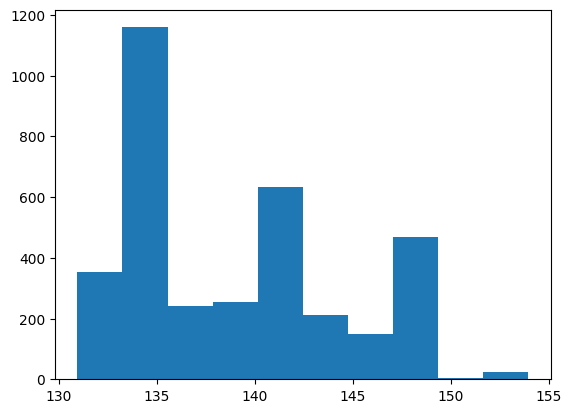

In [209]:
plt.hist(data['PartType5', 'particle_position_y'].in_units('Mpc'))

In [210]:
most_massive_bh_index = np.argmax(data['PartType5', 'BH_Mass'])

In [211]:
most_massive_bh_pos = data['PartType5', 'particle_position'][most_massive_bh_index]

In [212]:
most_massive_bh_pos.in_units('Mpc')

unyt_array([154.42104779, 133.19377298, 156.33786765], 'Mpc')

In [213]:
most_dyn_massive_bh_index = np.argmax(data['PartType5', 'Masses'])

In [214]:
most_dyn_massive_bh_pos = data['PartType5', 'particle_position'][most_dyn_massive_bh_index]

In [215]:
most_dyn_massive_bh_pos.in_units('Mpc')

unyt_array([151.64287684, 141.75004596, 143.88208869], 'Mpc')

# Get position of highest gas density

In [216]:
rho_max_index = np.argmax(data['gas', 'density'])

In [217]:
rho_max_pos = data['gas', 'position'][rho_max_index]

In [218]:
rho_max_pos.in_units('Mpc')

unyt_array([151.63900506, 141.74882812, 143.88254825], 'Mpc')

In [219]:
rho_max_part_pos = data['gas', 'particle_position'][rho_max_index]

In [220]:
rho_max_part_pos.in_units('Mpc')

unyt_array([151.63900506, 141.74882812, 143.88254825], 'Mpc')

# Centre on it - IGNORE

In [100]:
# gas_zoom_sphere = snap.sphere(gas_zoom_centre, gas_zoom_radius)

In [246]:
gas_zoom_sphere = snap.sphere(min_pot_pos, gas_zoom_radius)

In [247]:
gas_zoom_sphere

YTSphere (snap_halo_177_151): , center=[4.87558754e+26 3.81582781e+26 4.33832584e+26] cm, radius=9.91450765580987e+25 cm

In [248]:
list(gas_zoom_sphere.quantities.keys())

['WeightedAverageQuantity',
 'TotalQuantity',
 'TotalMass',
 'CenterOfMass',
 'BulkVelocity',
 'WeightedStandardDeviation',
 'AngularMomentumVector',
 'Extrema',
 'SampleAtMaxFieldValues',
 'MaxLocation',
 'SampleAtMinFieldValues',
 'MinLocation',
 'SpinParameter']

In [249]:
gas_zoom_sphere.quantities.total_mass().in_units('Msun')

unyt_array([2.89152240e+14, 6.97630841e+15], 'Msun')

In [250]:
baryon_mass, particle_mass = gas_zoom_sphere.quantities.total_quantity(
    [("gas", "mass"), ("all", "particle_mass")]
)

print(
    "Total mass in sphere is %0.3e Msun (gas = %0.3e Msun, particles = %0.3e Msun)"
    % (
        (baryon_mass + particle_mass).in_units("Msun"),
        baryon_mass.in_units("Msun"),
        particle_mass.in_units("Msun"),
    )
)

Total mass in sphere is 7.555e+15 Msun (gas = 2.892e+14 Msun, particles = 7.265e+15 Msun)


In [65]:
snap.data['gas', 'particle_position']

AttributeError: 'GizmoDataset' object has no attribute 'data'

In [ ]:
gas_zoom_data

# Calculate particle properties for getting IGrM - IGNORE

In [66]:
print(snap.field_info['gas', 'H_nuclei_density'].get_source())

def _nuclei_density(field, data):
    ftype = field.name[0]
    element = field.name[1][: field.name[1].find("_")]

    nuclei_mass_field = f"{element}_nuclei_mass_density"
    if (ftype, nuclei_mass_field) in data.ds.field_info:
        return (
            data[ftype, nuclei_mass_field]
            / ChemicalFormula(element).weight
            / data.ds.quan(1.0, "amu").in_cgs()
        )
    metal_field = f"{element}_metallicity"
    if (ftype, metal_field) in data.ds.field_info:
        return (
            data[ftype, "density"]
            * data[ftype, metal_field]
            / ChemicalFormula(element).weight
            / data.ds.quan(1.0, "amu").in_cgs()
        )

    field_data = np.zeros_like(
        data[ftype, f"{data.ds.field_info.species_names[0]}_number_density"]
    )
    for species in data.ds.field_info.species_names:
        nucleus = species
        if "_" in species:
            nucleus = species[: species.find("_")]
        # num is the number of nuclei contri

In [67]:
data['gas', 'H_nuclei_density']#.in_units('Mpc')

unyt_array([3.16280152, 2.67053787, 4.28792075, ..., 0.00925521, 0.01154859,
       0.00623445], shape=(2243885,), units='cm**(-3)')

In [68]:
igrm_zoom_sphere = gas_zoom_sphere.include_above(('gas', 'temperature'), 5e5, units='K')

In [69]:
igrm_zoom_sphere

YTCutRegion (snap_halo_3224_151): , base_object=YTSphere (snap_halo_3224_151): , center=[4.56831021e+26 4.32163911e+26 4.48607499e+26] cm, radius=5.98375241713127e+25 cm, conditionals=['obj["gas", "temperature"].in_units("K") > 500000.0']

In [70]:
igrm_zoom_sphere = igrm_zoom_sphere.include_below(('gas', 'H_nuclei_density'), 0.13, units='cm**-3')

In [71]:
igrm_zoom_sphere

YTCutRegion (snap_halo_3224_151): , base_object=YTSphere (snap_halo_3224_151): , center=[4.56831021e+26 4.32163911e+26 4.48607499e+26] cm, radius=5.98375241713127e+25 cm, conditionals=['obj["gas", "temperature"].in_units("K") > 500000.0', 'obj["gas", "H_nuclei_density"].in_units("cm**-3") < 0.13']

# Isolate IGrM

In [221]:
igrm = data.include_above(('PartType0', 'temperature'), 5e5, units='K')

In [222]:
igrm

YTCutRegion (snap_halo_3224_151): , base_object=YTRegion (snap_halo_3224_151): , center=[4.53776115e+26 4.53776115e+26 4.53776115e+26] cm, left_edge=[0. 0. 0.] cm, right_edge=[9.0755223e+26 9.0755223e+26 9.0755223e+26] cm, conditionals=['obj["PartType0", "temperature"].in_units("K") > 500000.0']

In [223]:
igrm = igrm.include_below(('PartType0', 'H_nuclei_density'), 0.13, units='cm**-3')

In [224]:
igrm

YTCutRegion (snap_halo_3224_151): , base_object=YTRegion (snap_halo_3224_151): , center=[4.53776115e+26 4.53776115e+26 4.53776115e+26] cm, left_edge=[0. 0. 0.] cm, right_edge=[9.0755223e+26 9.0755223e+26 9.0755223e+26] cm, conditionals=['obj["PartType0", "temperature"].in_units("K") > 500000.0', 'obj["PartType0", "H_nuclei_density"].in_units("cm**-3") < 0.13']

In [225]:
igrm = igrm.include_equal(('PartType0', 'DelayTime'), 0)

In [226]:
igrm

YTCutRegion (snap_halo_3224_151): , base_object=YTRegion (snap_halo_3224_151): , center=[4.53776115e+26 4.53776115e+26 4.53776115e+26] cm, left_edge=[0. 0. 0.] cm, right_edge=[9.0755223e+26 9.0755223e+26 9.0755223e+26] cm, conditionals=['obj["PartType0", "temperature"].in_units("K") > 500000.0', 'obj["PartType0", "H_nuclei_density"].in_units("cm**-3") < 0.13', 'obj["PartType0", "DelayTime"] == 0']

In [64]:
np.unique(data['PartType0', 'DelayTime'])

unyt_array([0.        , 0.00023264, 0.0002355 , ..., 0.19998483, 0.19999242,
       0.1999962 ], shape=(2972,), units='(dimensionless)')

In [65]:
len(np.where(data['PartType0', 'DelayTime']<=0)[0])

2239223

In [66]:
len(np.where(data['PartType0', 'DelayTime']<0)[0])

0

In [67]:
len(np.where(data['PartType0', 'DelayTime']>0)[0])

4662

In [68]:
len(np.where(data['PartType0', 'DelayTime']>=0)[0])

2243885

In [69]:
data['temperature']

unyt_array([  25797.66879416,   23575.68193607,   28798.36668821, ...,
         13975.93537793, 1156662.93874206, 2250617.02066724],
      shape=(2243885,), units='K')

In [70]:
igrm['temperature']

unyt_array([586776.95567996, 546719.64638791, 576091.21101491, ...,
       926707.71283458, 596770.65852898, 681300.96540995],
      shape=(1242555,), units='K')

In [71]:
igrm['gas', 'particle_position_x']

unyt_array([4.68445349e+26, 4.68808158e+26, 4.68251360e+26, ...,
       4.73609605e+26, 4.73592766e+26, 4.73613859e+26], shape=(1242555,), units='cm')

In [72]:
len(igrm['temperature'])

1242555

In [73]:
len(igrm['temperature'])

1242555

In [74]:
len(data['gas', 'temperature'])

2243885

# Calculate profile with yt profiles - IGNORE

In [72]:
igrm_entropy_profile = yt.create_profile(igrm_zoom_sphere, 
                                         ('index', 'radius'), ('gas', 'entropy'),
                                         units={("index", "radius"): "kpc"},
                                         logs={("index", "radius"): False},)

AttributeError: 'tuple' object has no attribute 'sampling_type'

In [88]:
igrm_entropy_profile = igrm_zoom_sphere.profile(bin_fields=('index', 'radius'),
                                                fields=('PartType0', 'gas_entropy'),
                                                n_bins=32,
                                                weight_field='mass',
#                                              units={("index", "radius"): "kpc"},
                                                units={("PartType0", "mass"):"Msun",
                                                       ('PartType0', 'gas_entropy'):'keV*cm**2'},
#                                          logs={("index", "radius"): False},)
                                               )

AttributeError: 'tuple' object has no attribute 'sampling_type'

In [84]:
igrm_entropy_profile

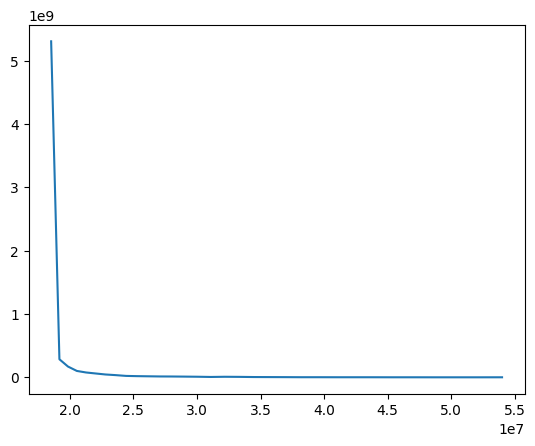

In [87]:
fig = plt.figure()
ax = fig.add_subplot(111)

ax.plot(
    igrm_entropy_profile.x.value,
    igrm_entropy_profile["PartType0", "gas_entropy"].value,
)

# ax.set_xlabel(r"$\mathrm{r\ (kpc)}$")
# ax.set_ylabel(r"$\mathrm{v_r\ (km/s)}$")

# Calculate profile manually

In [227]:
radial_bins = unyt.unyt_array(np.append([0], np.logspace(-1, np.log10(5), 20)), 'Mpc')

In [228]:
radial_bins

unyt_array([0.        , 0.1       , 0.12286254, 0.15095203, 0.18546349,
       0.22786514, 0.27996089, 0.34396705, 0.42260664, 0.51922523,
       0.63793329, 0.78378101, 0.96297323, 1.18313332, 1.4536276 ,
       1.78596373, 2.19428032, 2.69594844, 3.31231062, 4.06958881,
       5.        ], 'Mpc')

In [229]:
gas_zoom_centre.in_units('Mpc')

unyt_array([149.35924862, 138.86089154, 145.9805779 ], 'Mpc')

In [331]:
min_gas_pot_pos.in_units('Mpc')

unyt_array([158.159375  , 118.73426011, 163.45911075], 'Mpc')

In [332]:
max_gas_pot_pos.in_units('Mpc')

unyt_array([146.78929228, 154.64288833, 153.60229779], 'Mpc')

In [333]:
min_pot_pos.in_units('Mpc')

unyt_array([166.57077206, 255.77952665, 103.30428539], 'Mpc')

In [334]:
max_pot_pos.in_units('Mpc')

unyt_array([131.57659697, 245.0730239 , 205.30703125], 'Mpc')

In [231]:
most_massive_bh_pos.in_units('Mpc')

unyt_array([154.42104779, 133.19377298, 156.33786765], 'Mpc')

In [232]:
most_dyn_massive_bh_pos.in_units('Mpc')

unyt_array([151.64287684, 141.75004596, 143.88208869], 'Mpc')

In [233]:
rho_max_pos.in_units('Mpc')

unyt_array([151.63900506, 141.74882812, 143.88254825], 'Mpc')

In [234]:
igrm_pos_x = igrm['gas', 'particle_position_x']

In [235]:
igrm_pos_y = igrm['gas', 'particle_position_y']

In [236]:
igrm_pos_z = igrm['gas', 'particle_position_z']

In [237]:
gas_pos

unyt_array([[4.41465772e+26, 4.44821765e+26, 4.50202663e+26],
       [4.41571771e+26, 4.44893766e+26, 4.50194191e+26],
       [4.41547026e+26, 4.44892348e+26, 4.50094360e+26],
       ...,
       [4.48313289e+26, 4.18841239e+26, 4.61333721e+26],
       [4.48342181e+26, 4.18685891e+26, 4.61726272e+26],
       [4.48172512e+26, 4.18658275e+26, 4.61551072e+26]],
      shape=(17906273, 3), units='cm')

In [238]:
len(igrm_pos_x)

8620713

In [239]:
# igrm_zoom_radii = ((gas_pos[:,0]-gas_zoom_centre[0])**2 + 
#                   (gas_pos[:,1]-gas_zoom_centre[1])**2 + 
#                   (gas_pos[:,2]-gas_zoom_centre[2])**2)**0.5

In [240]:
igrm_zoom_radii_rel_centre = ((igrm_pos_x-gas_zoom_centre[0])**2 + 
                  (igrm_pos_y-gas_zoom_centre[1])**2 + 
                  (igrm_pos_z-gas_zoom_centre[2])**2)**0.5

In [335]:
igrm_zoom_radii_rel_min_gas_pot = ((igrm_pos_x-min_gas_pot_pos[0])**2 + 
                  (igrm_pos_y-min_gas_pot_pos[1])**2 + 
                  (igrm_pos_z-min_gas_pot_pos[2])**2)**0.5

In [336]:
igrm_zoom_radii_rel_max_gas_pot = ((igrm_pos_x-max_gas_pot_pos[0])**2 + 
                  (igrm_pos_y-max_gas_pot_pos[1])**2 + 
                  (igrm_pos_z-max_gas_pot_pos[2])**2)**0.5

In [337]:
igrm_zoom_radii_rel_min_pot = ((igrm_pos_x-min_pot_pos[0])**2 + 
                  (igrm_pos_y-min_pot_pos[1])**2 + 
                  (igrm_pos_z-min_pot_pos[2])**2)**0.5

In [338]:
igrm_zoom_radii_rel_max_pot = ((igrm_pos_x-max_pot_pos[0])**2 + 
                  (igrm_pos_y-max_pot_pos[1])**2 + 
                  (igrm_pos_z-max_pot_pos[2])**2)**0.5

In [339]:
igrm_zoom_radii_rel_bh_mass_max = ((igrm_pos_x-most_massive_bh_pos[0])**2 + 
                  (igrm_pos_y-most_massive_bh_pos[1])**2 + 
                  (igrm_pos_z-most_massive_bh_pos[2])**2)**0.5

In [340]:
igrm_zoom_radii_rel_bh_dyn_mass_max = ((igrm_pos_x-most_dyn_massive_bh_pos[0])**2 + 
                  (igrm_pos_y-most_dyn_massive_bh_pos[1])**2 + 
                  (igrm_pos_z-most_dyn_massive_bh_pos[2])**2)**0.5

In [341]:
igrm_zoom_radii_rel_rho_max = ((igrm_pos_x-rho_max_pos[0])**2 + 
                  (igrm_pos_y-rho_max_pos[1])**2 + 
                  (igrm_pos_z-rho_max_pos[2])**2)**0.5

In [245]:
# igrm_zoom_entropies = data['gas', 'entropy']

In [246]:
igrm_zoom_entropies = igrm['gas', 'entropy']

In [247]:
# gas_zoom_masses = data['gas', 'mass']

In [248]:
igrm_zoom_masses = igrm['gas', 'mass']

### Change this for the centre you want!

In [376]:
igrm_zoom_radii = igrm_zoom_radii_rel_bh_mass_max

In [377]:
igrm_zoom_radii.in_units('Mpc')

unyt_array([121.98094683, 121.97389267, 121.8953268 , ..., 129.02590619,
       129.07561309, 129.1058636 ], shape=(8620713,), units='Mpc')

In [378]:
entropy_profile_median = []
entropy_profile_mean = []
entropy_profile_mass_weighted = []
for bin_lo, bin_hi in zip(radial_bins[:-1], radial_bins[1:]):
#     print(bin_lo, bin_hi)
    radial_filter = np.logical_and(igrm_zoom_radii.in_units('Mpc').value>=bin_lo.in_units('Mpc').value,
                                   igrm_zoom_radii.in_units('Mpc').value<=bin_hi.in_units('Mpc').value)
#     print(np.where(radial_filter))
    entropies = igrm_zoom_entropies[radial_filter]
    masses = igrm_zoom_masses[radial_filter]
    print(len(entropies))
    print(len(masses))
#     print()
    
    entropy_profile_median.append(np.nanmedian(entropies))
    entropy_profile_mean.append(np.nanmean(entropies))
    if sum(masses)>0:
        K_mass = np.average(entropies, weights=masses)
        entropy_profile_mass_weighted.append(K_mass)
    else:
        entropy_profile_mass_weighted.append(np.nan)
    
    print(K_mass)
    print()

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV

0
0
142409.91073882487 cm**2*keV



In [379]:
entropy_profile_median

[unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV')]

In [380]:
entropy_profile_mean

[unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV'),
 unyt_quantity(nan, 'cm**2*keV')]

In [381]:
entropy_profile_mass_weighted

[nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan]

In [382]:
radial_bin_centres = (radial_bins[:-1] + radial_bins[1:])/2.

In [383]:
radial_bin_centres_logged = np.log10(radial_bin_centres)

In [384]:
log_radial_bin_centres = (np.log10(radial_bins[:-1]) + np.log10(radial_bins[1:]))/2.

In [385]:
log_radial_bin_centres_unlogged = 10**log_radial_bin_centres

In [386]:
plt.plot(radial_bin_centres, entropy_profile_median, label='median', lw=5)
plt.plot(radial_bin_centres, entropy_profile_median, label='mass-weighted', lw=1)
plt.plot(radial_bin_centres, entropy_profile_mean, label='mean', lw=2)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('R [kpc]')
plt.ylabel(r'K [keV $\mathrm{cm^2}$]')
plt.legend()

Error in callback <function _draw_all_if_interactive at 0x7fc604cf2b60> (for post_execute):


ValueError: Data has no positive values, and therefore cannot be log-scaled.

ValueError: Data has no positive values, and therefore cannot be log-scaled.

<Figure size 640x480 with 1 Axes>